In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
RANDOM_STATE = 24  # Remember to remove at the time of promotion to production(RANDOM_STATE = None) 
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE)

NOISE = 0.2
N_EPOCHS = 20000 # Number of Epochs
ALPHA = .02  # Learning Rate 
N_SAMPLES = 1000  # number of sample to create
TEST_SIZE = 0.2

params = {
    'legend.fontsize':'medium',
    'figure.figsize':(15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',
    'ytick.labelsize':'medium'
}
plt.rcParams.update(params)
CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid') # plt.style.use('ggplot')

## Helper Function

In [3]:
def plot_decison_boundary(model:dict, 
                          X_tr:np.ndarray,
                          y_tr:np.ndarray,
                          X_ts:np.ndarray,
                          y_ts:np.ndarray ):
    
    fig, ax = plt.subplots()
    dm = 0.01
    margin = 10 * dm
    X_min = min(X_tr[:,0].min() - margin, X_ts[:,0].min() - margin)
    X_max = max(X_tr[:,0].max() + margin, X_ts[:,0].max() + margin)
    y_min = min(X_tr[:,1].min() - margin, X_ts[:,1].min() - margin)
    y_max = max(X_tr[:,1].max() + margin, X_ts[:,1].max() + margin)

    xx, yy = np.meshgrid(np.arange(X_min, X_max, dm),
            np.arange(y_min, y_max, dm))

    XX = np.c_[xx.ravel(), yy.ravel()]
    Z = fn_predict(model, XX).reshape(xx.shape)

    ax.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    ax.scatter(X_tr[:,0], X_tr[:,1], c=y_tr, s=30, edgecolors='k', cmap=CMAP)
    ax.scatter(X_ts[:,0], X_ts[:,1], c=y_ts, s=30, marker='*', edgecolors='k', cmap=plt.cm.seismic)

    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.set_title('Decision Boundary')
    ax.legend()

In [4]:
X, y = datasets.make_moons(n_samples = N_SAMPLES,
                           shuffle = True,
                           noise = NOISE,
                           random_state = RANDOM_STATE)

X[:5], y[:5]

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [5]:
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=TEST_SIZE,
                                                   random_state=RANDOM_STATE,
                                                    stratify=y)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((800, 2), (200, 2), (800,), (200,))

## Sigmoid Activation Function

In [6]:
def fn_sigmoid(z):
    return 1/(1+np.exp(-z))

## Tanh Activation Function

In [7]:
def fn_active(z: np.ndarray) -> np.ndarray:
    return np.tanh(z)

def fn_active_prime(z: np.ndarray) -> np.ndarray:
    return 1.0-np.tanh(z)**2

In [8]:
fn_active(np.asarray([[-1, 0, 1],[-np.inf, 0, np.inf]]))

array([[-0.76159416,  0.        ,  0.76159416],
       [-1.        ,  0.        ,  1.        ]])

In [9]:
def fn_predict(model: dict, X_p: np.ndarray):
    ''' 
    model : Dictionary containing weights and bias
    X : input features
    '''
    W1, W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']

    # forward Propagation
    # Layer 1
    z1 = X_p.dot(W1) + b1 # Aggeragation
    a1 = fn_active(z1)

    # Layer 2
    z2 = a1.dot(W2) + b2 # Aggeragation
    a2 = fn_sigmoid(z2)
    
    return a2 >= 0.5 

In [10]:
def fn_calculate_loss(model: dict, X_l: np.ndarray, y_l: np.ndarray):
    ''' 
    model : Dictionary containing weights and bias
    X_l : input features
    y_l : target
    '''
    m = X_l.shape[0]
    W1, W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']

    # forward Propagation
    # Layer 1
    z1 = X_l.dot(W1) + b1 # Aggeragation
    a1 = fn_active(z1)

    # Layer 2
    z2 = a1.dot(W2) + b2 # Aggeragation
    a2 = fn_sigmoid(z2)

    data_loss = -(y_l * np.log(a2) + (1 - y_l) * np.log(1 - a2)).sum()
    return data_loss/m

In [11]:
def fn_build_model( nn_hdim: np.int64,
                    X: np.ndarray,
                    y: np.ndarray,
                    alpha: np.float64 = ALPHA,
                    n_epochs: np.int64 = N_EPOCHS
                  ) -> dict:
    '''
    nn_hdim: Numer of hidden units 
    X: features
    y: labels
    alpha: Learning Rate
    n_epochs: Number of passes through complete data for gradient decent
    '''
    m, nn_input_dim = X.shape
    nn_output_dim = y.shape[1]   

    w1 = rng.random((nn_input_dim, nn_hdim), dtype = np.float32) / np.sqrt(nn_input_dim)
    w2 = rng.random((nn_hdim, nn_output_dim), dtype = np.float32) / np.sqrt(nn_hdim)

    b1 = np.zeros((1,nn_hdim), dtype = np.float32)
    b2 = np.zeros((1,nn_output_dim), dtype = np.float32)

    curr_loss = 0
    loss, epoch = [], []

    for i in range(n_epochs):  # loop for number of epochs
        # forward Propagation
        # Layer 1        
        z1 = X.dot(w1) + b1 # Aggeragation
        a1 = fn_active(z1)
        
        # Layer 2
        z2 = a1.dot(w2) + b2 # Aggeragation
        a2 = fn_sigmoid(z2)

        # Back propagation
        # Layer 2
        dz2 = a2 - y
        dw2 = (a1.T).dot(dz2)
        assert (w2.shape == dw2.shape), f'Shape -> W2: {w2.shape} | dw2: {dw2.shape}'

        db2 = np.sum(dz2, axis=0, keepdims=True)
        assert (b2.shape == db2.shape), f'Shape -> b2: {b2.shape} | db2: {db2.shape}'

        da1 = dz2.dot(w2.T)
        assert (a1.shape == da1.shape), f'Shape -> a1: {a1.shape} | da1: {da1.shape}'

        # Layer 1
        dz1 = da1 * fn_active_prime(z1)
        
        dw1 = (X.T).dot(dz1)
        assert (w1.shape == dw1.shape), f'Shape -> W1: {w1.shape} | dw1: {dw1.shape}'

        db1 = np.sum(dz1, axis=0, keepdims=True)
        assert (b1.shape == db1.shape), f'Shape -> b1: {b1.shape} | db1: {db1.shape}'

        # Gradient Update 
        w1 = w1 - alpha * dw1 / m
        w2 = w2 - alpha * dw2 / m
        b1 = b1 - alpha * db1 / m
        b2 = b2 - alpha * db2 / m

        model = {'W1': w1, 'W2': w2, 'b1': b1, 'b2': b2}

        if i % 100 == 0:
            curr_loss = fn_calculate_loss(model = model, X_l = X, y_l = y)
            loss.append(curr_loss)
            epoch.append(i)
            print(f'Epoch {i:3d} : Loss = {curr_loss:.4f}')

    loss_hist['epoch'] = epoch
    loss_hist['loss'] = loss
    return model

In [12]:
loss_hist = {'epoch':[],
            'loss':[]}
y_train = y_train.reshape(-1, 1)
model = fn_build_model(32, X_train, y_train)

Epoch   0 : Loss = 0.7843
Epoch 100 : Loss = 0.7455
Epoch 200 : Loss = 0.7152
Epoch 300 : Loss = 0.6912
Epoch 400 : Loss = 0.6714
Epoch 500 : Loss = 0.6547
Epoch 600 : Loss = 0.6400
Epoch 700 : Loss = 0.6266
Epoch 800 : Loss = 0.6142
Epoch 900 : Loss = 0.6024
Epoch 1000 : Loss = 0.5910
Epoch 1100 : Loss = 0.5800
Epoch 1200 : Loss = 0.5692
Epoch 1300 : Loss = 0.5586
Epoch 1400 : Loss = 0.5482
Epoch 1500 : Loss = 0.5380
Epoch 1600 : Loss = 0.5280
Epoch 1700 : Loss = 0.5181
Epoch 1800 : Loss = 0.5085
Epoch 1900 : Loss = 0.4992
Epoch 2000 : Loss = 0.4900
Epoch 2100 : Loss = 0.4812
Epoch 2200 : Loss = 0.4726
Epoch 2300 : Loss = 0.4643
Epoch 2400 : Loss = 0.4563
Epoch 2500 : Loss = 0.4487
Epoch 2600 : Loss = 0.4413
Epoch 2700 : Loss = 0.4342
Epoch 2800 : Loss = 0.4275
Epoch 2900 : Loss = 0.4211
Epoch 3000 : Loss = 0.4149
Epoch 3100 : Loss = 0.4091
Epoch 3200 : Loss = 0.4035
Epoch 3300 : Loss = 0.3982
Epoch 3400 : Loss = 0.3932
Epoch 3500 : Loss = 0.3884
Epoch 3600 : Loss = 0.3839
Epoch 3700 

In [13]:
df_hist = pd.DataFrame(loss_hist, columns=['Epochs','Loss'])
df_hist.head()

,Epochs,Loss


In [14]:
y_pred = fn_predict(model = model, X_p = X_train)
accuracy_score(y_train, y_pred)

0.97

In [15]:
y_pred = fn_predict(model = model, X_p = X_test)
accuracy_score(y_test, y_pred)

0.965

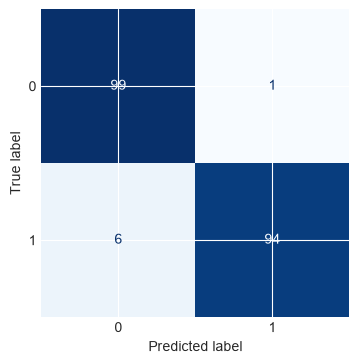

In [16]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
fig, ax = plt.subplots(figsize=(4,4))
disp.plot(ax=ax,cmap='Blues',colorbar=False)

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_15300\3539083497.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


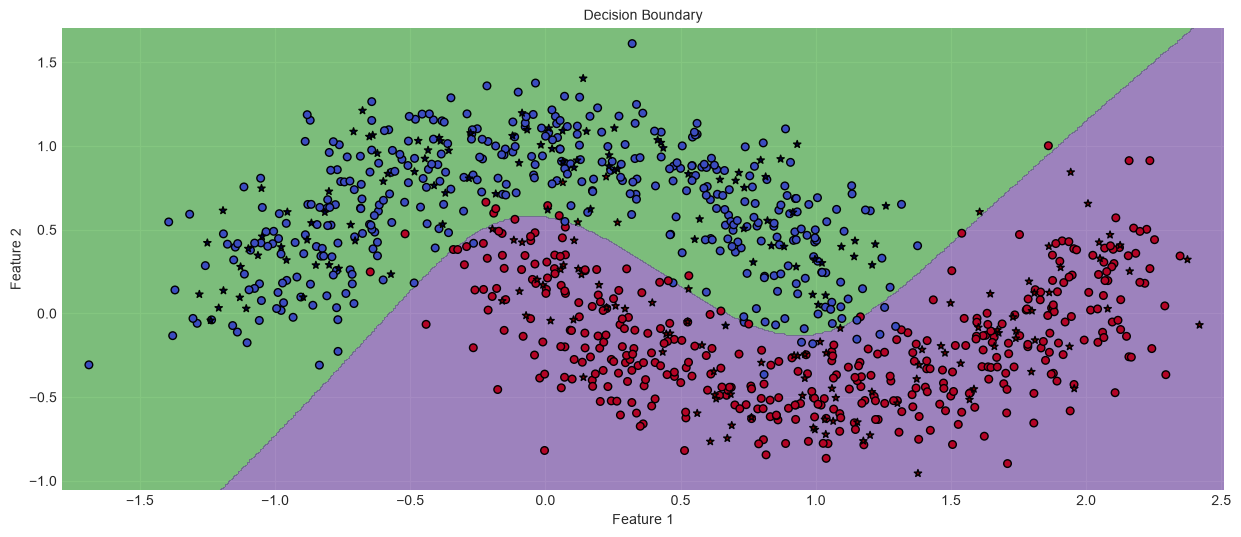

In [17]:
plot_decison_boundary(model,X_train,y_train,X_test,y_test)